# Laboratório I · Fundamentos do Bitcoin
*Bitcoin na Veia: do halving ao ETF*, 2ª edição, Flávio Lemos, CMT

Dados até **30/09/2026**. O laboratório refaz, com as próprias regras do protocolo, a curva de emissão e os 33 halvings, confere o hash do bloco gênese, mostra a prova de trabalho em miniatura e mede, com dados da Blockchain.com, a oferta, a taxa de hash, a dificuldade e o uso da rede, testa o Bitcoin como moeda, faz a conta do minerador e mede o que sobrou das bifurcações. Serve aos Capítulos 1 a 4. O Capítulo 19 da *Análise Técnica dos Mercados Financeiros*, 4ª edição, usa a mesma base de dados.

In [ ]:
!pip install -q yfinance

In [2]:
import hashlib
import json
import logging
import os
import struct
import time
import urllib.request
import numpy as np
import pandas as pd
import yfinance as yf

logging.getLogger("yfinance").setLevel(logging.CRITICAL)
FIM = "2026-10-01"                      # dados até 30/09/2026
RAW = "https://raw.githubusercontent.com/traderbrasil/livro-bitcoin-na-veia/main/labs/dados/"
def baixa(nome):
    """Usa a cópia dos dados salva no GitHub do livro (mesmos números do livro); sem ela, baixa tudo de novo."""
    if not os.path.exists(nome):
        try:
            import urllib.request
            urllib.request.urlretrieve(RAW + nome, nome)
        except Exception:
            pass
    return os.path.exists(nome)
CACHE = "dados_lab1.pkl"
pc = lambda x, k=0: f"{x:.{k}%}".replace(".", ",")
nr = lambda x, k=0: f"{x:,.{k}f}".replace(",", "X").replace(".", ",").replace("X", ".")
CADEIA = {"oferta": "total-bitcoins", "hash": "hash-rate", "dificuldade": "difficulty",
          "transacoes": "n-transactions", "taxas_btc": "transaction-fees", "taxas_usd": "transaction-fees-usd"}


def blockchain_com(nome):
    url = f"https://api.blockchain.info/charts/{nome}?timespan=all&format=json&sampled=false"
    for tentativa in range(5):                                   # o servidor às vezes demora ou derruba a conexão
        try:
            v = json.loads(urllib.request.urlopen(url, timeout=60).read())["values"]
            break
        except Exception:
            if tentativa == 4:
                raise
            time.sleep(3)
    s_ = pd.Series({pd.to_datetime(x["x"], unit="s"): x["y"] for x in v})
    return s_.loc[:"2026-09-30 23:59"]

if baixa(CACHE):
    D = pd.read_pickle(CACHE)
else:
    D = {k: blockchain_com(v) for k, v in CADEIA.items()}
    px = yf.download(["BTC-USD", "^IXIC", "GLD", "^BVSP", "BRL=X"], start="2014-01-01", end=FIM, auto_adjust=True,
                     progress=False)["Close"]
    D["btc"] = px["BTC-USD"]
    D["precos"] = px
    D["forks"] = yf.download(["BTC-USD", "BCH-USD", "BSV-USD", "BTG-USD"], start="2017-01-01", end=FIM,
                             auto_adjust=True, progress=False)["Close"]
    pd.to_pickle(D, CACHE)

## Parte 1: a emissão pelas regras do protocolo

In [3]:
SAT = 100_000_000                       # 1 bitcoin = 100 milhões de satoshis
INTERVALO = 210_000                     # blocos entre um halving e outro
DATAS = {0: "03/01/2009", 1: "28/11/2012", 2: "09/07/2016", 3: "11/05/2020", 4: "20/04/2024"}
eras, total = [], 0
for i in range(64):
    sub = (50 * SAT) >> i               # a mesma conta do código do Bitcoin Core: desloca um bit a cada halving
    if sub == 0:
        break
    total += sub * INTERVALO
    eras.append((i, i * INTERVALO, sub / SAT, total / SAT))
TAB_EMIS = pd.DataFrame(eras, columns=["era", "bloco_inicial", "recompensa", "oferta_no_fim"])
print(f"Parte 1. {len(eras)} eras com recompensa; o {len(eras)}º halving, no bloco {nr(len(eras) * INTERVALO)},"
      f" leva a recompensa a zero")
print(f"   Oferta máxima: {nr(total / SAT, 8)} BTC (um pouco menos de 21 milhões, por causa do arredondamento)")
print("   era  bloco inicial  recompensa  oferta no fim da era  % de 21 milhões  início")
for e in eras[:6]:
    print(f"   {e[0]:>3}  {nr(e[1]):>13}  {nr(e[2], 4):>10}  {nr(e[3], 2):>20}  {pc(e[3] / 21e6, 2):>15}  "
          f"{DATAS.get(e[0], 'por volta de ' + str(2028 + 4 * (e[0] - 5)))}")
print(f"   Último satoshi por volta de {2009 + round(len(eras) * INTERVALO * 10 / 60 / 24 / 365.25)} "
      f"(estimativa com 10 minutos por bloco)")

Parte 1. 33 eras com recompensa; o 33º halving, no bloco 6.930.000, leva a recompensa a zero
   Oferta máxima: 20.999.999,97690000 BTC (um pouco menos de 21 milhões, por causa do arredondamento)
   era  bloco inicial  recompensa  oferta no fim da era  % de 21 milhões  início
     0              0     50,0000         10.500.000,00           50,00%  03/01/2009
     1        210.000     25,0000         15.750.000,00           75,00%  28/11/2012
     2        420.000     12,5000         18.375.000,00           87,50%  09/07/2016
     3        630.000      6,2500         19.687.500,00           93,75%  11/05/2020
     4        840.000      3,1250         20.343.750,00           96,88%  20/04/2024
     5      1.050.000      1,5625         20.671.875,00           98,44%  por volta de 2028
   Último satoshi por volta de 2141 (estimativa com 10 minutos por bloco)


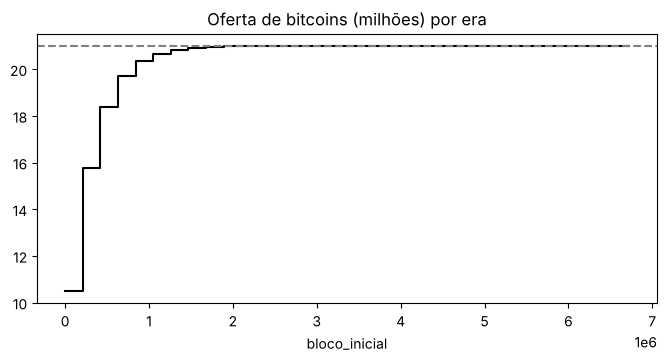

In [4]:
import matplotlib.pyplot as plt
ax = TAB_EMIS.set_index("bloco_inicial")["oferta_no_fim"].div(1e6).plot(drawstyle="steps-post", figsize=(8, 3.5),
                                                                        color="black", title="Oferta de bitcoins (milhões) por era")
ax.axhline(21, color="gray", ls="--")
plt.show()

## Parte 2: o bloco gênese confere

In [5]:
# cabeçalho de 80 bytes do bloco 0, publicado em 03/01/2009
versao, anterior = 1, bytes(32)
merkle = bytes.fromhex("4a5e1e4baab89f3a32518a88c31bc87f618f76673e2cc77ab2127b7afdeda33b")[::-1]
tempo, bits, nonce = 1231006505, 0x1d00ffff, 2083236893
cab = struct.pack("<I", versao) + anterior + merkle + struct.pack("<III", tempo, bits, nonce)
h = hashlib.sha256(hashlib.sha256(cab).digest()).digest()[::-1].hex()
alvo = (bits & 0xffffff) * 2 ** (8 * ((bits >> 24) - 3))
print(f"Parte 2. Cabeçalho do bloco gênese: {len(cab)} bytes; data {pd.to_datetime(tempo, unit='s'):%d/%m/%Y %H:%M} UTC")
print(f"   hash duplo SHA-256: {h}")
print(f"   começa com {len(h) - len(h.lstrip('0'))} zeros em hexadecimal; abaixo do alvo? {int(h, 16) < alvo}")
assert h == "000000000019d6689c085ae165831e934ff763ae46a2a6c172b3f1b60a8ce26f"

Parte 2. Cabeçalho do bloco gênese: 80 bytes; data 03/01/2009 18:15 UTC
   hash duplo SHA-256: 000000000019d6689c085ae165831e934ff763ae46a2a6c172b3f1b60a8ce26f
   começa com 10 zeros em hexadecimal; abaixo do alvo? True


## Parte 3: prova de trabalho em miniatura

In [6]:
TAB_POW = []
print("Parte 3. Procura de um nonce que faça o hash começar com N zeros (texto: 'Bitcoin na Veia')")
print("   zeros  tentativas  esperado (16^N)  segundos")
for n in range(1, 7):
    t0, nonce = time.time(), 0
    while not hashlib.sha256(f"Bitcoin na Veia{nonce}".encode()).hexdigest().startswith("0" * n):
        nonce += 1
    TAB_POW.append((n, nonce + 1, 16 ** n, time.time() - t0))
    print(f"   {n:>5}  {nr(nonce + 1):>10}  {nr(16 ** n):>15}  {nr(time.time() - t0, 2):>8}")
print("   Cada zero a mais multiplica o trabalho esperado por 16. Verificar a resposta custa um único hash.")

Parte 3. Procura de um nonce que faça o hash começar com N zeros (texto: 'Bitcoin na Veia')
   zeros  tentativas  esperado (16^N)  segundos
       1          27               16      0,00
       2         506              256      0,00
       3       5.031            4.096      0,01
       4      85.503           65.536      0,12


       5   3.179.335        1.048.576      3,27


       6  18.900.771       16.777.216     22,27
   Cada zero a mais multiplica o trabalho esperado por 16. Verificar a resposta custa um único hash.


## Parte 4: oferta, taxa de hash e dificuldade

In [7]:
of = D["oferta"].dropna()
hs = D["hash"].dropna()
df_ = D["dificuldade"].dropna()
btc = D["btc"].dropna()
ult = of.index[-1]
emit_ano = 144 * 3.125 * 365
print(f"Parte 4. Oferta em {ult:%d/%m/%Y}: {nr(of.iloc[-1])} BTC, {pc(of.iloc[-1] / 21e6, 1)} dos 21 milhões;"
      f" faltam {nr(21e6 - of.iloc[-1])} BTC")
print(f"   Emissão atual: 144 blocos x 3,125 = 450 BTC por dia, cerca de {nr(emit_ano)} por ano,"
      f" {pc(emit_ano / of.iloc[-1], 2)} da oferta (inflação da oferta)")
print(f"   Bitcoin em 30/09/2026: US$ {nr(btc.iloc[-1])}; 450 BTC por dia valem US$ {nr(450 * btc.iloc[-1] / 1e6, 1)} milhões")
h17 = hs.loc["2017-12"].mean()
h30 = hs.rolling(30).mean().iloc[-1]
print(f"   Taxa de hash: {nr(h17 / 1e6, 1)} milhões de TH/s em dez/2017 (1ª edição) e {nr(h30 / 1e6)} milhões de TH/s"
      f" hoje (média de 30 dias), {nr(h30 / h17)} vezes mais")
print(f"   Dificuldade: {nr(df_.loc['2017-12'].mean() / 1e12, 2)} trilhões em dez/2017 e {nr(df_.iloc[-1] / 1e12, 1)}"
      f" trilhões em {df_.index[-1]:%m/%Y}")

Parte 4. Oferta em 30/09/2026: 20.091.781 BTC, 95,7% dos 21 milhões; faltam 908.219 BTC
   Emissão atual: 144 blocos x 3,125 = 450 BTC por dia, cerca de 164.250 por ano, 0,82% da oferta (inflação da oferta)
   Bitcoin em 30/09/2026: US$ 83.554; 450 BTC por dia valem US$ 37,6 milhões
   Taxa de hash: 13,4 milhões de TH/s em dez/2017 (1ª edição) e 945 milhões de TH/s hoje (média de 30 dias), 70 vezes mais
   Dificuldade: 1,67 trilhões em dez/2017 e 132,8 trilhões em 09/2026


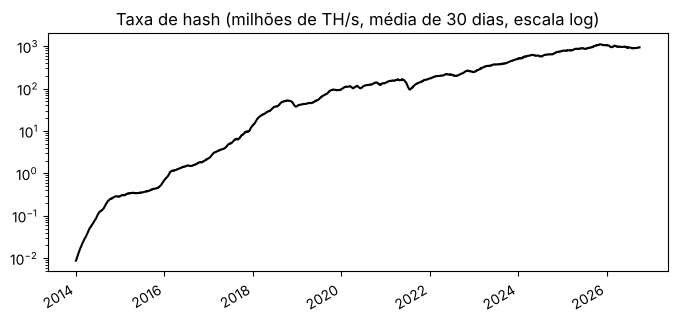

In [8]:
ax = (hs.rolling(30).mean() / 1e6).loc["2014":].plot(logy=True, figsize=(8, 3.5), color="black",
                                                    title="Taxa de hash (milhões de TH/s, média de 30 dias, escala log)")
plt.show()

## Parte 5: uso da rede e as taxas

In [9]:
tx = D["transacoes"].dropna()
fee = D["taxas_btc"].dropna()
A = pd.DataFrame({"tx": tx.resample("YE").mean(), "taxas": fee.resample("YE").mean()}).loc["2016":]
TAB_USO = []
print("Parte 5. Média diária por ano: transações e taxas pagas aos mineradores (em BTC)")
print("   ano   transações/dia   taxas/dia (BTC)   taxas / recompensa do bloco")
SUB = {y: (25 if y < 2016.5 else 12.5 if y < 2020.4 else 6.25 if y < 2024.3 else 3.125) for y in range(2016, 2027)}
for d, r in A.iterrows():
    sub_dia = 144 * SUB[d.year]
    TAB_USO.append((d.year, r["tx"], r["taxas"], r["taxas"] / sub_dia))
    print(f"   {d.year}  {nr(r['tx']):>15}  {nr(r['taxas'], 1):>16}  {pc(r['taxas'] / sub_dia, 1):>26}")
print("   (2016, 2020 e 2024 misturam duas recompensas; a coluna usa a do fim do ano)")

Parte 5. Média diária por ano: transações e taxas pagas aos mineradores (em BTC)
   ano   transações/dia   taxas/dia (BTC)   taxas / recompensa do bloco
   2016          225.756              61,6                        1,7%
   2017          285.105             275,0                       15,3%
   2018          223.002              70,4                        3,9%
   2019          328.174              54,2                        3,0%
   2020          307.523              71,9                        4,0%
   2021          267.935              58,8                        6,5%
   2022          255.086              14,7                        1,6%
   2023          420.318              64,2                        7,1%
   2024          525.269              41,5                        4,6%
   2025          420.660               4,7                        1,1%
   2026          580.240               2,9                        0,6%
   (2016, 2020 e 2024 misturam duas recompensas; a coluna usa a do

## Parte 6: o Bitcoin como moeda (volatilidade, correlação, quedas e custo de pagar)

In [10]:
C = D["precos"]
DIAS = pd.DataFrame({"btc": C["BTC-USD"], "nasdaq": C["^IXIC"], "ouro": C["GLD"], "ibov": C["^BVSP"],
                     "dolar": C["BRL=X"]}).ffill(limit=3)
UTEIS = DIAS[DIAS.index.dayofweek < 5].pct_change(fill_method=None)   # só dias úteis, para comparar com a bolsa
TAB_MOEDA = []
print("Parte 6a. Volatilidade anualizada (dias úteis) e correlação diária do Bitcoin, por ano")
print("   ano    BTC  Nasdaq  ouro  Ibovespa  dólar/real | corr. Nasdaq  corr. ouro")
for ano in range(2015, 2027):
    x = UTEIS.loc[str(ano)].dropna()
    v = x.std() * np.sqrt(252)
    lin = (ano, v["btc"], v["nasdaq"], v["ouro"], v["ibov"], v["dolar"], x["btc"].corr(x["nasdaq"]),
           x["btc"].corr(x["ouro"]))
    TAB_MOEDA.append(lin)
    print(f"   {ano}  {pc(lin[1]):>5} {pc(lin[2]):>6} {pc(lin[3]):>5} {pc(lin[4]):>7} {pc(lin[5]):>10}   |"
          f"    {lin[6]:+.2f}       {lin[7]:+.2f}".replace(".", ","))
print("   (2026 vai até 30/09)")
QUEDAS = []
print("\nParte 6b. As grandes quedas do Bitcoin (fechamento diário em dólar)")
for nome, ini, fim in [("2017-2018", "2017-06-01", "2019-03-31"), ("2021-2022", "2021-06-01", "2023-01-31"),
                       ("2025-2026", "2025-06-01", "2026-09-30")]:
    x = btc.loc[ini:fim]
    topo = x.idxmax(); fundo = x.loc[topo:].idxmin()
    QUEDAS.append((nome, topo, x[topo], fundo, x[fundo], x[fundo] / x[topo] - 1))
    print(f"   {nome}: topo US$ {nr(x[topo])} em {topo:%d/%m/%Y}; fundo US$ {nr(x[fundo])} em {fundo:%d/%m/%Y};"
          f" queda de {pc(x[fundo] / x[topo] - 1)}")
fee_tx = (D["taxas_usd"] / D["transacoes"]).dropna()
TAB_TAXA = fee_tx.resample("YE").mean().loc["2016":]
print("\nParte 6c. Taxa média por transação na rede, em dólar (média dos dias de cada ano)")
for d, v in TAB_TAXA.items():
    print(f"   {d.year}: US$ {nr(v, 2)}")
print(f"   Maior média diária: US$ {nr(fee_tx.max(), 2)} em {fee_tx.idxmax():%d/%m/%Y}")

Parte 6a. Volatilidade anualizada (dias úteis) e correlação diária do Bitcoin, por ano
   ano    BTC  Nasdaq  ouro  Ibovespa  dólar/real | corr. Nasdaq  corr. ouro
   2015    66%    17%   14%     23%        21%   |    +0,03       -0,01
   2016    49%    16%   16%     26%        19%   |    -0,02       +0,09
   2017    91%     9%   10%     19%        17%   |    +0,05       -0,02
   2018    76%    20%    9%     21%        17%   |    +0,08       -0,03
   2019    68%    15%   12%     17%        14%   |    -0,10       +0,19
   2020    71%    35%   19%     43%        22%   |    +0,45       +0,30
   2021    78%    18%   13%     20%        17%   |    +0,28       +0,01
   2022    63%    31%   15%     21%        18%   |    +0,59       +0,16
   2023    46%    17%   13%     17%        12%   |    +0,19       +0,11
   2024    56%    18%   15%     13%        13%   |    +0,35       +0,09
   2025    39%    24%   19%     15%        12%   |    +0,46       +0,13
   2026    44%    19%   30%     18%        1

## Parte 7: a segurança da prova de trabalho e a conta do minerador

In [11]:
H = hs.rolling(30).mean().iloc[-1] * 1e12          # hashes por segundo (média de 30 dias)
ANO_S = 365.25 * 24 * 3600
print("Parte 7a. Força bruta contra o SHA-256 com toda a rede de 30/09/2026")
print(f"   Taxa de hash: {H:.2e} hashes por segundo".replace(".", ","))
for nome, tent in [("achar uma colisão (2^128 tentativas)", 2 ** 128), ("achar a entrada de um hash (2^256)", 2 ** 256)]:
    print(f"   {nome}: {tent / H / ANO_S:.1e} anos".replace(".", ","))
print("   (idade do universo: cerca de 1,4e10 anos)")
dif = df_.iloc[-1]
alvo = 0xffff * 2 ** 208 / dif
zeros = 256 - np.log2(alvo)
print(f"\nParte 7b. Dificuldade em 30/09/2026: {nr(dif / 1e12, 1)} trilhões")
print(f"   O hash do bloco precisa começar com cerca de {zeros:.0f} bits zero ({zeros / 4:.0f} zeros em hexadecimal);"
      f" o bloco gênese precisou de 32 bits")
print(f"   Hashes esperados por bloco: dificuldade x 2^32 = {dif * 2 ** 32:.1e}; em 600 segundos,"
      f" {dif * 2 ** 32 / 600:.2e} hashes por segundo".replace(".", ","))
mud = df_[df_.diff() != 0].pct_change().dropna()
mud = mud[mud.index > "2010-12-31"]
print("\nParte 7c. Os maiores ajustes de dificuldade desde 2011 (série diária da Blockchain.com, que aproxima os"
      " ajustes; o corte exato de 03/07/2021 foi de quase 28%)")
for d, v in mud.nsmallest(3).items():
    print(f"   queda: {d:%d/%m/%Y} {pc(v, 1)}")
for d, v in mud.nlargest(3).items():
    print(f"   alta:  {d:%d/%m/%Y} {ps(v, 1) if 'ps' in globals() else pc(v, 1)}")
h21 = hs.loc["2021"].rolling(7).mean()
print(f"   China, 2021: taxa de hash (média de 7 dias) de {nr(h21.loc['2021-05'].max() / 1e6)} milhões de TH/s em maio"
      f" para {nr(h21.loc['2021-06':'2021-07'].min() / 1e6)} milhões em {h21.loc['2021-06':'2021-07'].idxmin():%d/%m/%Y}")
USD = D["precos"]["BRL=X"].dropna().iloc[-1]
taxa30 = fee.loc["2026-09"].mean()
rec_rede = (450 + taxa30) * btc.iloc[-1]
print(f"\nParte 7d. Receita de todos os mineradores em set/2026: {nr(450 + taxa30, 1)} BTC por dia"
      f" (450 de recompensa e {nr(taxa30, 1)} de taxas), cerca de US$ {nr(rec_rede / 1e6, 1)} milhões por dia")
TH, JTH, TARIFA = 244, 12.5, 0.80               # hipóteses: máquina a ar eficiente de 2026 e tarifa residencial
kw = TH * JTH / 1000
custo = kw * 24 * TARIFA
receita = TH * 1e12 / H * (450 + taxa30) * btc.iloc[-1] * USD
print(f"   Conta de uma máquina em casa (hipóteses: {TH} TH/s, {nr(JTH, 1)} J/TH, R$ {nr(TARIFA, 2)} por kWh,"
      f" dólar a R$ {nr(USD, 2)}):")
print(f"   consumo {nr(kw, 2)} kW, {nr(kw * 24, 1)} kWh por dia; energia R$ {nr(custo, 2)} por dia;"
      f" receita R$ {nr(receita, 2)} por dia; resultado R$ {nr(receita - custo, 2)} por dia, sem contar a máquina")
print(f"   Tarifa em que a conta empata: R$ {nr(receita / (kw * 24), 2)} por kWh")

Parte 7a. Força bruta contra o SHA-256 com toda a rede de 30/09/2026
   Taxa de hash: 9,45e+20 hashes por segundo
   achar uma colisão (2^128 tentativas): 1,1e+10 anos
   achar a entrada de um hash (2^256): 3,9e+48 anos
   (idade do universo: cerca de 1,4e10 anos)

Parte 7b. Dificuldade em 30/09/2026: 132,8 trilhões
   O hash do bloco precisa começar com cerca de 79 bits zero (20 zeros em hexadecimal); o bloco gênese precisou de 32 bits
   Hashes esperados por bloco: dificuldade x 2^32 = 5,7e+23; em 600 segundos, 9,50e+20 hashes por segundo

Parte 7c. Os maiores ajustes de dificuldade desde 2011 (série diária da Blockchain.com, que aproxima os ajustes; o corte exato de 03/07/2021 foi de quase 28%)
   queda: 03/07/2021 -21,6%
   queda: 01/11/2011 -18,0%
   queda: 30/05/2021 -15,3%
   alta:  27/05/2011 78,1%
   alta:  24/06/2011 57,3%
   alta:  19/05/2011 55,1%
   China, 2021: taxa de hash (média de 7 dias) de 181 milhões de TH/s em maio para 85 milhões em 02/07/2021

Parte 7d. Receita d

## Parte 8: o que aconteceu com as bifurcações

In [12]:
F = D["forks"].where(D["forks"] > 0)
TAB_FORK = []
print("Parte 8. Bifurcações do Bitcoin contra o próprio Bitcoin (fechamento diário em dólar, Yahoo Finance)")
print("   moeda  desde        US$ no início  US$ em 30/09/2026  em dólar  máxima (data)            em bitcoins")
for t, nome in [("BCH-USD", "BCH"), ("BSV-USD", "BSV"), ("BTG-USD", "BTG")]:
    x = F[t].dropna(); b = F["BTC-USD"].reindex(x.index)
    ini, fim = x.index[0], x.index[-1]
    em_btc = (x.iloc[-1] / b.iloc[-1]) / (x.iloc[0] / b.iloc[0]) - 1
    TAB_FORK.append((nome, ini, x.iloc[0], x.iloc[-1], x.iloc[-1] / x.iloc[0] - 1, x.max(), x.idxmax(), em_btc))
    print(f"   {nome:<5}  {ini:%d/%m/%Y}  {nr(x.iloc[0], 2):>13}  {nr(x.iloc[-1], 2):>17}  {pc(x.iloc[-1] / x.iloc[0] - 1):>8}"
          f"  {nr(x.max(), 2)} ({x.idxmax():%d/%m/%Y})  {pc(em_btc):>10}")
b = F["BTC-USD"].dropna()
print(f"   BTC    09/11/2017  {nr(b.loc['2017-11-09'], 2):>13}  {nr(b.iloc[-1], 2):>17}"
      f"  {pc(b.iloc[-1] / b.loc['2017-11-09'] - 1):>8}")
print("   (o Yahoo só tem BCH e BTG a partir de 09/11/2017, alguns meses depois de cada bifurcação)")

Parte 8. Bifurcações do Bitcoin contra o próprio Bitcoin (fechamento diário em dólar, Yahoo Finance)
   moeda  desde        US$ no início  US$ em 30/09/2026  em dólar  máxima (data)            em bitcoins
   BCH    09/11/2017         654,30             305,88      -53%  3.923,07 (20/12/2017)        -96%
   BSV    09/11/2018          68,75              19,94      -71%  441,39 (16/04/2021)        -98%
   BTG    09/11/2017         156,66               0,87      -99%  453,45 (20/12/2017)       -100%
   BTC    09/11/2017       7.143,58          83.553,85     1070%
   (o Yahoo só tem BCH e BTG a partir de 09/11/2017, alguns meses depois de cada bifurcação)


## Para ir além
1. Na Parte 1, quanto da oferta já existia em cada halving? Em que ano passam a faltar menos de 100 mil bitcoins?
2. Na Parte 3, troque o texto e repita. O número de tentativas muda, a média esperada não.
3. Na Parte 5, troque as taxas em bitcoins por taxas em dólar (`transaction-fees-usd`). O que muda quando o preço sobe?
4. Na Parte 6, calcule a correlação em janelas de 90 dias em vez de por ano. Ela fica estável?
5. Na Parte 7, troque a tarifa e a máquina. Com que preço do Bitcoin a mineração em casa empata?
6. Na Parte 8, meça as bifurcações a partir da máxima de cada uma. Quanto caíram em bitcoins?

**Governança:** os resultados valem só para os dados e as datas usadas. A Parte 1 é regra do protocolo e não muda; as Partes 4 e 5 são dados de mercado, sempre com data.

━━━━━━━━━━━━━━━━━━━━━━━

⚠️ AVISO LEGAL (DISCLAIMER):

━━━━━━━━━━━━━━━━━━━━━━━

Todo o conteúdo deste livro  é estritamente educacional e informativo. 

Não constitui, em nenhuma hipótese, recomendação de compra ou venda de ativos financeiros. 

Testes passados não são garantias de resultados futuros.

Investimentos envolvem riscos, incluindo a perda total do capital investido. 

Consulte sempre um profissional habilitado antes de tomar qualquer decisão de investimento.